## -1. Налаштування середовища

### -1.0. Імпортуємо бібліотеки

In [106]:
import sys
import os
import math
import time
import random
import json

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

import pandas as pd
import gc

### -1.1. Перевіряємо чи ми точно в Colab

In [108]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має виконуватися в Google Colab (https://colab.research.google.com/)"


Running in Colab: True


#### -1.2. Використовуємо графічний прискорювач, якщо доступний.
На Colab зазвичай є безкоштовний GPU (T4).
Використовуємо його, якщо він доступний.
Якщо ні, залишаємося на CPU.

In [109]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Використовуємо: cpu


#### -1.3. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінти mini-GPT й логи TensorBoard пережили
перезапуск.

In [110]:
from google.colab import drive
drive.mount("/content/drive")

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")

os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab3


# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?

    **Відповідь**: 1. Можлива оптимізація. 2. На стиках між віршами токенізатор порахував би частоту пар букв між останнім словом попереднього твору і першим словом наступного. Алгоритм міг би створити штучні токени, складені з кінця одного вірша і початку іншого, які насправді не існують і не мають сенсу.

2. З який (який?) етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
  
    **Відповідь**:
  
    1. Normalization (Нормалізація): Базова чистка вхідного сирого рядка (приведення до нижнього регістру, видалення зайвих пробілів, нормалізація Unicode на кшталт NFC/NFKC, заміна специфічних символів).

    2. Pre-tokenization (Попередня токенізація): Розбиття тексту на грубі "слова" або блоки (найчастіше за пробілами та пунктуацією). Це задає межі, за які алгоритм злиття підслів не має права виходити (наприклад, ByteLevel розбиває текст на байти/слова, щоб токен не об'єднував кінець одного слова з початком іншого без пробілу).

    3. Model: Власне алгоритм підслів. Отримує нарізані шматки після pre-tokenization і розбиває їх на токени зі свого навченого словника.

    4. Post-processing: Додавання спеціальних службових токенів (наприклад,<eos>, <unk>), генерація масок уваги (attention_mask) і token_type_ids для подачі безпосередньо в нейромережу.


3. Що таке `"<unk>", "<eos>"` в 2.1.?
  
    **Відповідь**:

    \<unk> (Unknown): Спеціальний токен, яким замінюються будь-які символи або послідовності, відсутні у словнику токенізатора.

    \<eos> (End of Sequence / Stream): Службовий токен позначення завершення тексту (документа, вірша або генерації)


4. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).

In [5]:
from datasets import load_dataset

poems_dataset = load_dataset("RudyiVT/ukrainian-poems", split="train")
poems_df = poems_dataset.to_pandas()
poems_iterator = poems_df["context_poem"].dropna().tolist()

README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…): reconstructing file:   0%|          |  0.00B / 58.6MB            

data/train-00000-of-00001-3d92810ccd3206(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

In [6]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

# ------------------------------------------------------------------------------

bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(vocab_size=16000, special_tokens=["<unk>", "<eos>"])
bpe_tokenizer.train_from_iterator(poems_iterator, trainer=bpe_trainer)

# ------------------------------------------------------------------------------

bpe_tokenizer_small = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer_small.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer_small.decoder = decoders.ByteLevel()

bpe_trainer_small = trainers.BpeTrainer(vocab_size=4000, special_tokens=["<unk>", "<eos>"])
bpe_tokenizer_small.train_from_iterator(poems_iterator, trainer=bpe_trainer_small)

In [7]:
unk_id_orig = bpe_tokenizer.token_to_id("<unk>")
unk_id_small = bpe_tokenizer_small.token_to_id("<unk>")

enc_orig = bpe_tokenizer.encode_batch(poems_iterator)
enc_small = bpe_tokenizer_small.encode_batch(poems_iterator)

avg_len_orig = sum(len(e.ids) for e in enc_orig) / len(poems_iterator)
avg_len_small = sum(len(e.ids) for e in enc_small) / len(poems_iterator)

avg_unk_ratio_orig = sum(e.ids.count(unk_id_orig) for e in enc_orig) / len(poems_iterator)
avg_unk_ratio_small = sum(e.ids.count(unk_id_small) for e in enc_small) / len(poems_iterator)

print(f"Середня к-сть токенів (vocab=16000): {avg_len_orig:.1f}")
print(f"Середня к-сть токенів (vocab=4000): {avg_len_small:.1f}")

print(f"Середня к-сть <unk> (vocab=16000): {avg_unk_ratio_orig}")
print(f"Середня к-сть <unk> (vocab=4000): {avg_unk_ratio_small}")

Середня к-сть токенів (vocab=16000): 1027.1
Середня к-сть токенів (vocab=4000): 1247.1
Середня к-сть <unk> (vocab=16000): 0.0
Середня к-сть <unk> (vocab=4000): 0.0


In [8]:
del poems_iterator, poems_df, poems_dataset

**Пояснення**:

**Чому частка \<unk> не зростає:** При використанні BPE базовий словник містить усі 256 можливих байтів. Будь-який невідомий символ завжди можна розкласти на послідовність базових байтів, тому частка \<unk> залишається близькою до 0%.

**Чому зростає довжина послідовності та як це впливає на CONTEXT_LEN**:
При малому розмірі словника алгоритм вивчає менше злиттів частин слів. Слова нарізаються на коротші шматочки (часто по 1-2 літери чи байти), відповідно один вірш кодується значно більшою кількістю токенів.

**Як це впливає на модель?:** Оскільки у моделі фіксоване вікно CONTEXT_LEN=64, при малому словнику вона фізично бачить менший відрізок тексту(кількість токенів) за один прохід, що погіршує врахування довготривалого контексту.

5. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
  
  **Відповідь**: `<eos>` позначає межу між рядками. Якщо склеїти тексти без `<eos>`, модель на стику почне вчитися тому, що останній рядок одного рядка продовжується першим рядком зовсім іншого твору іншого автора.

6. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
  
  **Відповідь**: Одновимірні тензори PyTorch (torch.Tensor) типу torch.int64, розмірністю (N).

7. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
  
  **Відповідь**:
  ```python
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])

    assert torch.equal(x[:, 1:], y[:, :-1]), "Невідповідність зсуву між x та y у батчі!"
    
    return x.to(device), y.to(device)
  ```

8. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
  
**Відповідь**:

У нижньотрикутній матриці рядок i відповідає токену на позиції i, а стовпчик j — токену на позиції j. Токен i має право звертати увагу лише на токени j <= i (поточний і попередні). Верхньотрикутна маска, навпаки, змусила б модель бачити тільки майбутнє і забувати минуле.
    
Без маски матриця уваги, модель просто списуватиме відповідь із наступної позиції i+1, яка вже присутня у вхідному рядку, замість вивчення залежностей.

9. 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
  
**Відповідь**: Останній та найкращий чекпоінти збігаються коли модель стабільно вчиться впродовж усіх ітерацій, функція втрат val_loss монотонно спадає аж до кінця, і явище перенавчання (overfitting) ще не настало. Вони не збігаються коли настає перенавчання. Після досягнення мінімуму val_loss починає зростати (або незмінюється) (модель зазубрює навчальний корпус), тоді як train_loss продовжує падати.

10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
  
**Відповідь**: Крива стала помітно інформативнішою: фіксуються дрібні зміни та точний момент початку перенавчання.

11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.

**Відповідь**: Перед застосуванням Softmax сирі логіти діляться на температуру $T$. При низькій температурі модель збільшує вагу найбільших логітів та обирає лише найімовірніші варіанти. При високій температурі різниця між логітами зменшується, модель обирає варіанти більш рівномірно.

12. За що саме відповідає параметр `top_p`?
      
**Відповідь**: top_p обмежує набір кандидатів для вибірки лише тими токенами, чия накопичена ймовірність досягає порогу p (наприклад, 0.9).

13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.
    
**Відповідь**: параметер enable_thinking=True активує режим ланцюжка міркувань. Модель перед формуванням фінальної відповіді генерує блок думок. У відповіді з'являється блок внутрішніх міркувань, де модель аналізує промпт, продумує сюжет, і лише після видає продовження.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

### 1.1. Завантажуємо датасет з Hugging Face Hub

In [116]:
from datasets import load_dataset

speeches_dataset = load_dataset(
    "slava-medvedev/zelensky-speeches",
    split="train",
    streaming=True
)

speeches_df = speeches_dataset.to_pandas()
speeches_df = speeches_df[speeches_df["lang"] == "uk"]

print(f"Матеріалізовано документів: {len(speeches_df)}")
print("Колонки:", speeches_df.columns.tolist())

Матеріалізовано документів: 1854
Колонки: ['date', 'link', 'topic', 'full_text', 'lang']


### 1.2. Збираємо суцільний корпус

In [6]:
corpus_text = "\n\n".join(speeches_df["full_text"].dropna().tolist())

print("Розмір корпусу:", len(corpus_text), "символів")
print("Перші 500 символів корпусу:\n", corpus_text[:500])

Розмір корпусу: 7842799 символів
Перші 500 символів корпусу:
 Шановні громадяни України! На нашій планеті живе близько п’яти тисяч народів. Їхній портрет, архетип, ментальність – це заплутана павутина історичних подій для етнографів. Але є одна річ, яка, на мій погляд, просто, але досить точно змальовує характер народу. Це його державні свята. Те, що об’єднує всіх, тож є важливим для всіх. 21 листопада – саме такий день. Відповідь на питання: хто такі українці та що для них головне? Ми відзначаємо сьогодні День Гідності та Свободи. Свято, яке показує, що д


### 1.3. Базова статистика корпусу

In [7]:
words = corpus_text.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):   ", len(words))
print("Унікальних слів:      ", len(unique_words))
print("Приклад уривку:\n")
print(corpus_text[:500])

del words
del unique_words
gc.collect()

Слів (з повторами):    1168629
Унікальних слів:       81679
Приклад уривку:

Шановні громадяни України! На нашій планеті живе близько п’яти тисяч народів. Їхній портрет, архетип, ментальність – це заплутана павутина історичних подій для етнографів. Але є одна річ, яка, на мій погляд, просто, але досить точно змальовує характер народу. Це його державні свята. Те, що об’єднує всіх, тож є важливим для всіх. 21 листопада – саме такий день. Відповідь на питання: хто такі українці та що для них головне? Ми відзначаємо сьогодні День Гідності та Свободи. Свято, яке показує, що д


559

---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [12]:
VOCAB_SIZE = 500
UNK_TOKEN = "<unk>"
EOS_TOKEN = "<eos>"
SPECIAL_TOKENS = ["<unk>", "<pad>", "<bos>", "<eos>", "<mask>"]

speeches_iterator = speeches_df["full_text"].dropna().tolist()

from tokenizers import Tokenizer, models, normalizers, trainers, pre_tokenizers, decoders
from transformers import AutoTokenizer

### 2.1. Тренування нового токенізатора на основі старого



In [13]:
old_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
new_tokenizer = old_tokenizer.train_new_from_iterator(speeches_iterator, VOCAB_SIZE)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

### 2.2. BPE

In [14]:
bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer.decoder = decoders.ByteLevel()
bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
bpe_tokenizer.train_from_iterator(speeches_iterator, trainer=bpe_trainer)

### 2.3. Word-Piece

In [15]:
wp_tokenizer = Tokenizer(models.WordPiece(unk_token=UNK_TOKEN))
wp_tokenizer.normalizer = normalizers.Sequence(
    [
        normalizers.NFC(),
        normalizers.Lowercase(),
    ]
)
wp_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
wp_tokenizer.decoder = decoders.WordPiece(prefix="##")
wp_trainer = trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    unk_token=UNK_TOKEN,
    continuing_subword_prefix="##",
)
wp_tokenizer.train_from_iterator(speeches_iterator, trainer=wp_trainer)

### 2.4. Unigram

In [16]:
unk_id = SPECIAL_TOKENS.index(UNK_TOKEN)
unigram_tokenizer = Tokenizer(models.Unigram())
unigram_tokenizer.normalizer = normalizers.Sequence(
    [
        normalizers.NFKC(),
        normalizers.Lowercase(),
    ]
)
unigram_tokenizer.pre_tokenizer = pre_tokenizers.Metaspace()
unigram_tokenizer.decoder = decoders.Metaspace()
unigram_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    unk_token=UNK_TOKEN,
)
unigram_tokenizer.train_from_iterator(speeches_iterator, trainer=unigram_trainer)

### 2.5. Приклади кодування

In [17]:
print("Text sample: ", corpus_text[:100])

tokens = old_tokenizer.tokenize(corpus_text[:100])
print("Using pretrained tokenizer:")
print("Tokens: {",";".join(tokens[:100]), "}")
print("Token's cout: ", len(tokens))

tokens = new_tokenizer.tokenize(corpus_text[:100])
print("Using trained tokenizer:")
print("Tokens: {",";".join(tokens[:100]), "}")
print("Token's cout: ", len(tokens))

tokens = bpe_tokenizer.encode(corpus_text[:100]).tokens
print("Using bpe tokenizer:")
print("Tokens: {",";".join(tokens[:100]), "}")
print("Token's cout: ", len(tokens))

tokens = wp_tokenizer.encode(corpus_text[:100]).tokens
print("Using wp tokenizer:")
print("Tokens: {",";".join(tokens[:100]), "}")
print("Token's cout: ", len(tokens))

tokens = unigram_tokenizer.encode(corpus_text[:100]).tokens
print("Using unigram tokenizer:")
print("Tokens: {",";".join(tokens[:100]), "}")
print("Token's cout: ", len(tokens))

Text sample:  Шановні громадяни України! На нашій планеті живе близько п’яти тисяч народів. Їхній портрет, архетип
Using pretrained tokenizer:
Tokens: { Ð¨;Ð°Ð½;Ð¾Ð²;Ð½;Ñĸ;ĠÐ³;ÑĢÐ¾Ð¼;Ð°Ð´;Ñı;Ð½Ð¸;ĠÐ£ÐºÑĢÐ°;ÑĹ;Ð½Ð¸;!;ĠÐĿÐ°;ĠÐ½Ð°ÑĪ;Ñĸ;Ð¹;ĠÐ¿Ð»Ð°Ð½;ÐµÑĤ;Ñĸ;ĠÐ¶Ð¸Ð²;Ðµ;ĠÐ±;Ð»Ð¸Ð·;ÑĮ;ÐºÐ¾;ĠÐ¿;âĢĻ;ÑıÑĤÐ¸;ĠÑĤ;Ð¸Ñģ;Ñı;Ñĩ;ĠÐ½Ð°;ÑĢÐ¾Ð´;Ñĸ;Ð²;.;ĠÐ;ĩ;Ñħ;Ð½;Ñĸ;Ð¹;ĠÐ¿Ð¾ÑĢ;ÑĤÑĢ;ÐµÑĤ;,;ĠÐ°;ÑĢ;Ñħ;ÐµÑĤ;Ð¸Ð¿ }
Token's cout:  54
Using trained tokenizer:
Tokens: { Ð;¨;Ð°Ð½;Ð¾Ð²;Ð½Ñĸ;ĠÐ³;ÑĢÐ¾Ð;¼;Ð°Ð´;Ñı;Ð½Ð¸;ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸;!;ĠÐĿ;Ð°;ĠÐ½Ð°ÑĪ;ÑĸÐ¹;ĠÐ¿;Ð»;Ð°Ð½;ÐµÑĤ;Ñĸ;ĠÐ¶;Ð¸Ð²;Ðµ;ĠÐ±;Ð»;Ð¸Ð;·;ÑĮÐº;Ð¾;ĠÐ¿;âĢ;Ļ;Ñı;ÑĤÐ¸;Ġ;ÑĤÐ¸;ÑģÑı;Ñĩ;ĠÐ½Ð°;ÑĢÐ¾Ð´;ÑĸÐ²;.;ĠÐ;ĩ;Ñħ;Ð½;ÑĸÐ¹;ĠÐ¿;Ð¾ÑĢ;ÑĤÑĢ;ÐµÑĤ;,;ĠÐ°;ÑĢ;Ñħ;ÐµÑĤ;Ð¸Ð;¿ }
Token's cout:  60
Using bpe tokenizer:
Tokens: { Ð;¨;Ð°Ð½;Ð¾Ð²;Ð½Ñĸ;ĠÐ³;ÑĢÐ¾Ð;¼;Ð°Ð´;Ñı;Ð½Ð¸;ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸;!;ĠÐĿ;Ð°;ĠÐ½Ð°ÑĪ;ÑĸÐ¹;ĠÐ¿;Ð»;Ð°Ð½;ÐµÑĤ;Ñĸ;ĠÐ¶;Ð¸Ð²;Ðµ;ĠÐ±;Ð»;Ð¸Ð;·;ÑĮÐº;Ð¾;ĠÐ¿;âĢĻ;Ñı;ÑĤÐ¸;Ġ;ÑĤÐ¸;ÑģÑı;Ñĩ;ĠÐ½Ð°;ÑĢÐ¾Ð´;ÑĸÐ²;.;ĠÐ;ĩ;Ñħ;Ð½;ÑĸÐ¹;ĠÐ¿;Ð¾ÑĢ;ÑĤÑĢ;ÐµÑĤ;,;ĠÐ°;ÑĢ;Ñħ;ÐµÑĤ;Ð¸Ð;¿ }
Token's cou

### 2.6. Порівняння

In [18]:
sample_text = corpus_text[:50000]
freq_word = "на"
rare_word = "потрібний"

tokenizers_dict = {
    "Byte-Level BPE": bpe_tokenizer,
    "WordPiece": wp_tokenizer,
    "Unigram": unigram_tokenizer,
}

for name, tok in tokenizers_dict.items():
    s_tokens = tok.encode(sample_text).tokens
    f_tokens = tok.encode(freq_word).tokens
    r_tokens = tok.encode(rare_word).tokens
    print(
        f"{name:15} | Vocab: {tok.get_vocab_size():3} | Sample len: {len(s_tokens):5} | Freq ('{freq_word}'): {len(f_tokens)} | Rare ('{rare_word}'): {len(r_tokens)}"
    )

Byte-Level BPE  | Vocab: 500 | Sample len: 26208 | Freq ('на'): 1 | Rare ('потрібний'): 5
WordPiece       | Vocab: 500 | Sample len: 24785 | Freq ('на'): 1 | Rare ('потрібний'): 4
Unigram         | Vocab: 500 | Sample len: 24747 | Freq ('на'): 1 | Rare ('потрібний'): 2


---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

### 3.1. Корпус і токенізація

#### Тренуємо токенізатор

In [111]:
from tokenizers import Tokenizer, models, normalizers, trainers, pre_tokenizers, decoders
from transformers import AutoTokenizer

UNK_TOKEN = "<unk>"
EOS_TOKEN = "<eos>"
SPECIAL_TOKENS = ["<unk>", "<pad>", "<bos>", "<eos>", "<mask>"]

def prepare_tokenizer(speeches_df, vocab_size: int, force_retrain: bool = False):
  tok_path = os.path.join(ARTIFACT_DIR, f"tokenizer_{vocab_size}.json")

  if os.path.exists(tok_path) and not force_retrain:
    print(f"Завантаження токенізатора з {tok_path}...")
    tokenizer = Tokenizer.from_file(tok_path)
  else:
    print(f"Тренування Unigram-токенізатора (vocab_size={vocab_size})...")
    speeches_iterator = speeches_df["full_text"].dropna().tolist()

    tokenizer = Tokenizer(models.Unigram())
    tokenizer.normalizer = normalizers.NFC()
    tokenizer.pre_tokenizer = pre_tokenizers.Metaspace()
    tokenizer.decoder = decoders.Metaspace()

    trainer = trainers.UnigramTrainer(
      vocab_size=vocab_size,
      special_tokens=SPECIAL_TOKENS,
      unk_token=UNK_TOKEN,
    )
    tokenizer.train_from_iterator(speeches_iterator, trainer=trainer)
    tokenizer.save(tok_path)
  return tokenizer


#### Кодуємо корпус

In [112]:
def prepare_data(
    speeches_df: pd.DataFrame,
    tokenizer: Tokenizer,
    vocab_size: int,
    force_retrain: bool = False,
    batch_size: int = 1000
    ) -> torch.Tensor:

  data_path = os.path.join(ARTIFACT_DIR, f"data_{vocab_size}.pt")

  if os.path.exists(data_path) and not force_retrain:
      print(f"Завантаження токенізованих даних з {data_path}...")
      saved_data = torch.load(data_path)
      train_data, val_data = saved_data["train"], saved_data["val"]
  else:
    print("Кодування корпусу пачками...")
    eos_id = tokenizer.token_to_id(EOS_TOKEN)
    unk_id = tokenizer.token_to_id(UNK_TOKEN)

    speeches_list = speeches_df["full_text"].dropna().tolist()
    token_id_chunks = []

    for start in range(0, len(speeches_list), batch_size):
        batch = speeches_list[start:start + batch_size]
        encodings = tokenizer.encode_batch(batch)
        for enc in encodings:
            token_id_chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
        del encodings

    token_ids = np.concatenate(token_id_chunks)
    unk_share = (token_ids == unk_id).mean()
    print(f"Всього токенів: {len(token_ids):,} | Частка <unk>: {unk_share:.4%}")

    data = torch.from_numpy(token_ids.astype(np.int64))
    split_idx = int(len(data) * 0.9)
    train_data = data[:split_idx]
    val_data = data[split_idx:]

    torch.save({"train": train_data, "val": val_data}, data_path)
    del token_ids, token_id_chunks, data
    gc.collect()

  print(f"Train: {train_data.shape} | val: {val_data.shape}\n")
  return train_data, val_data

---
### 3.2. Архітектура моделі і генератор батчів



In [113]:
def get_batch(source: torch.Tensor, context_len: int, batch_size: int = 64):
    ix = torch.randint(len(source) - context_len - 1, (batch_size,))
    x = torch.stack([source[i:i + context_len] for i in ix])
    y = torch.stack([source[i + 1:i + context_len + 1] for i in ix])
    return x.to(device), y.to(device)

class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)
        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),  # GELU краще підходить для сучасних трансформерів, ніж ReLU
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 0.8, top_k: int | None = 40):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

### 3.3. Тренування 2 варіантів моделі

1. Baseline: Компактна модель (CONTEXT_LEN=64, N_LAYERS=4, EMBED_DIM=128).

1. Deeper & Long Context: Збільшене контекстне вікно (CONTEXT_LEN=128), глибша модель (N_LAYERS=6, EMBED_DIM=192, N_HEADS=6).

#### Функція експеременту

In [114]:
def run_experiment(
    exp_name: str,
    config: dict,
    train_data: torch.Tensor,
    val_data: torch.Tensor,
    force_retrain: bool = False
    ) -> tuple[MiniGPT, dict]:

    exp_dir = os.path.join(ARTIFACT_DIR, "models", exp_name)
    os.makedirs(exp_dir, exist_ok=True)

    first_ckpt_path = os.path.join(exp_dir, "first_model.pt")
    best_ckpt_path = os.path.join(exp_dir, "best_model.pt")
    history_path = os.path.join(exp_dir, "history.json")

    model = MiniGPT(
        vocab_size=config["vocab_size"],
        embed_dim=config["embed_dim"],
        n_heads=config["n_heads"],
        n_layers=config["n_layers"],
        context_len=config["context_len"],
        dropout=config["dropout"]
    ).to(device)

    n_params = sum(p.numel() for p in model.parameters())

    if os.path.exists(best_ckpt_path) and os.path.exists(history_path) and not force_retrain:
        print(f"Завантаження моделі з кешу ({exp_dir})...")
        model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
        with open(history_path, "r", encoding="utf-8") as f:
            history = json.load(f)
        print(f"Параметрів: {n_params:,} | Найкращий val_loss: {history['best_val_loss']:.3f} (iter {history['best_iter']})\n")
        return model, history

    print(f"Експеримент: {exp_name}")
    print(f"Параметрів моделі: {n_params:,} | Пристрій: {device}")

    optimizer = torch.optim.AdamW(model.parameters(), lr=config["lr"])
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, exp_name))

    best_val_loss = float("inf")
    best_iter = 0

    history = {
        "exp_name": exp_name,
        "config": config,
        "n_params": n_params,
        "first_ckpt_path": first_ckpt_path,
        "best_ckpt_path": best_ckpt_path,
        "iters": [],
        "train_losses": [],
        "val_losses": [],
        "best_val_loss": float("inf"),
        "best_iter": 0,
        "train_time_min": 0.0
    }

    @torch.no_grad()
    def estimate_loss() -> dict[str, float]:
        model.eval()
        out = {}
        for split, src in (("train", train_data), ("val", val_data)):
            losses = torch.zeros(config["eval_iters"])
            for i in range(config["eval_iters"]):
                xb, yb = get_batch(src, config["context_len"], config["batch_size"])
                _, loss = model(xb, yb)
                losses[i] = loss.item()
            out[split] = losses.mean().item()
        model.train()
        return out

    start_time = time.time()

    for it in range(config["max_iters"]):
        xb, yb = get_batch(train_data, config["context_len"], config["batch_size"])
        _, loss = model(xb, yb)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % config["eval_interval"] == 0 or it == config["max_iters"] - 1:
            losses = estimate_loss()
            elapsed_min = (time.time() - start_time) / 60

            writer.add_scalar("Loss/train", losses["train"], it)
            writer.add_scalar("Loss/val", losses["val"], it)
            history["iters"].append(it)
            history["train_losses"].append(losses["train"])
            history["val_losses"].append(losses["val"])

            if it == 0:
                torch.save(model.state_dict(), first_ckpt_path)

            if losses["val"] < history["best_val_loss"]:
                history["best_val_loss"] = losses["val"]
                history["best_iter"] = it
                torch.save(model.state_dict(), best_ckpt_path)

            print(
                f"iter {it} | train_loss={losses['train']:.3f} | "
                f"val_loss={losses['val']:.3f} | {elapsed_min:.1f} хв"
            )

    history["train_time_min"] = round((time.time() - start_time) / 60, 2)
    writer.close()

    with open(history_path, "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2, ensure_ascii=False)

    model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
    print(f"Модель натреновано за {history['train_time_min']} хв. Найкращий val_loss={history['best_val_loss']:.3f} (iter {history['best_iter']})\n")
    return model, history

#### Запускаємо експеремент

In [118]:
from torch.utils.tensorboard import SummaryWriter

FORCE_RETRAIN = False

tok_4k = prepare_tokenizer(speeches_df, vocab_size=4000, force_retrain=FORCE_RETRAIN)
train_4k, val_4k = prepare_data(speeches_df, tok_4k, vocab_size=4000, force_retrain=FORCE_RETRAIN)

tok_8k = prepare_tokenizer(speeches_df, vocab_size=8000, force_retrain=FORCE_RETRAIN)
train_8k, val_8k = prepare_data(speeches_df, tok_8k, vocab_size=8000, force_retrain=FORCE_RETRAIN)

config_v1 = { # Конфігурація 1 (Baseline)
    "vocab_size": tok_4k.get_vocab_size(),
    "context_len": 64,
    "embed_dim": 128,
    "n_heads": 4,
    "n_layers": 4,
    "dropout": 0.1,
    "batch_size": 64,
    "lr": 3e-4,
    "max_iters": 8000,
    "eval_interval": 250,
    "eval_iters": 50
}
config_v2 = { # Конфігурація 2 (Більший контекст і глибша мережа)
    "vocab_size": tok_8k.get_vocab_size(),
    "context_len": 128,
    "embed_dim": 192,
    "n_heads": 6,
    "n_layers": 6,
    "dropout": 0.1,
    "batch_size": 64,
    "lr": 3e-4,
    "max_iters": 8000,
    "eval_interval": 250,
    "eval_iters": 50
}

model_v1, hist_v1 = run_experiment("mini_gpt_v1", config_v1, train_4k, val_4k, force_retrain=FORCE_RETRAIN)
model_v2, hist_v2 = run_experiment("mini_gpt_v2", config_v2, train_8k, val_8k, force_retrain=FORCE_RETRAIN)


# Those lines were add because of pain of multiple retrains...
# There are no words to describe my pain...
model_save_dir = os.path.join(ARTIFACT_DIR, "models", "minigpt_v1.pt")
torch.save(model_v1.state_dict(), model_save_dir)
model_save_dir = os.path.join(ARTIFACT_DIR, "models", "minigpt_v2.pt")
torch.save(model_v1.state_dict(), model_save_dir )

Завантаження токенізатора з /content/drive/MyDrive/ai_systems/lab3/tokenizer_4000.json...
Завантаження токенізованих даних з /content/drive/MyDrive/ai_systems/lab3/data_4000.pt...
Train: torch.Size([1828901]) | val: torch.Size([203212])

Завантаження токенізатора з /content/drive/MyDrive/ai_systems/lab3/tokenizer_8000.json...
Завантаження токенізованих даних з /content/drive/MyDrive/ai_systems/lab3/data_8000.pt...
Train: torch.Size([1589409]) | val: torch.Size([176602])

Завантаження моделі з кешу (/content/drive/MyDrive/ai_systems/lab3/models/mini_gpt_v1)...
Параметрів: 1,828,000 | Найкращий val_loss: 4.075 (iter 7999)

Завантаження моделі з кешу (/content/drive/MyDrive/ai_systems/lab3/models/mini_gpt_v2)...
Параметрів: 5,770,688 | Найкращий val_loss: 4.214 (iter 7750)



### 3.9. Крива навчання

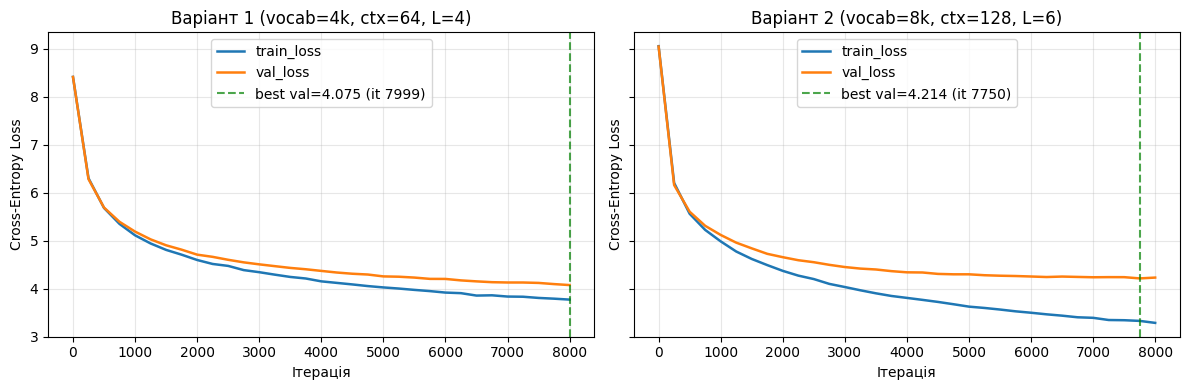






| Модель      |   Vocab |   Context | Layers / Heads   | Параметрів   |   Best Val Loss |   Best Iter |   Час (хв) |
|:------------|--------:|----------:|:-----------------|:-------------|----------------:|------------:|-----------:|
| mini_gpt_v1 |    4000 |        64 | 4 / 4            | 1,828,000    |           4.075 |        7999 |       4.85 |
| mini_gpt_v2 |    8000 |       128 | 6 / 6            | 5,770,688    |           4.214 |        7750 |       9.62 |


In [121]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
experiments = [
    ("Варіант 1 (vocab=4k, ctx=64, L=4)", hist_v1),
    ("Варіант 2 (vocab=8k, ctx=128, L=6)", hist_v2),
]

for ax, (title, hist) in zip(axes, experiments):
    ax.plot(hist["iters"], hist["train_losses"], label="train_loss", linewidth=1.8)
    ax.plot(hist["iters"], hist["val_losses"], label="val_loss", linewidth=1.8)
    ax.axvline(hist["best_iter"], color="green", linestyle="--", alpha=0.7,
               label=f"best val={hist['best_val_loss']:.3f} (it {hist['best_iter']})")
    ax.set_title(title)
    ax.set_xlabel("Ітерація")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(4 * "\n")

summary_df = pd.DataFrame([
    {
        "Модель": h["exp_name"],
        "Vocab": h["config"]["vocab_size"],
        "Context": h["config"]["context_len"],
        "Layers / Heads": f"{h['config']['n_layers']} / {h['config']['n_heads']}",
        "Параметрів": f"{h['n_params']:,}",
        "Best Val Loss": round(h["best_val_loss"], 3),
        "Best Iter": h["best_iter"],
        "Час (хв)": h["train_time_min"]
    }
    for h in (hist_v1, hist_v2)
])
print(summary_df.to_markdown(index=False))
summary_df.to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=False, encoding="utf-8-sig")

### 3.10. Генерація на різних стадіях тренування

Порівнюємо якість тексту на першому збереженому чекпоінті (майже випадкова
ініціалізація) і на найкращому за val_loss (не обов'язково останньому —
модель могла почати переучуватись ближче до кінця тренування) — той самий
промпт в обох випадках.

In [14]:
def generate_from_ckpt(
    model: MiniGPT,
    ckpt_path: str,
    tokenizer: Tokenizer,
    prompt: str,
    max_new_tokens: int = 80,
    temperature: float = 1.0,
    top_k: int = 40
) -> str:
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    prompt_ids = torch.tensor([tokenizer.encode(prompt).ids], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens=max_new_tokens, temperature=temperature, top_k=top_k)
    return tokenizer.decode(out_ids[0].tolist())

PROMPT1 = "Сьогодні я провів розмову із"
PROMPT2 = "Шановні громадяни України! Сьогодні ми"

print("\n=== Варіант 1: Найкращий чекпоінт ===")
print(generate_from_ckpt(model_v1, hist_v1["best_ckpt_path"], tok_4k, PROMPT1))
print(generate_from_ckpt(model_v1, hist_v1["best_ckpt_path"], tok_4k, PROMPT2))

print("\n=== Варіант 2: Найкращий чекпоінт ===")
print(generate_from_ckpt(model_v2, hist_v2["best_ckpt_path"], tok_8k, PROMPT1))
print(generate_from_ckpt(model_v2, hist_v2["best_ckpt_path"], tok_8k, PROMPT2))



=== Варіант 1: Найкращий чекпоінт ===
Сьогодні я провів розмову із Президентом Фінляндії, міністрів закордонних справ Луганщина, міністра оборони, з питань охорони здоров’я – наших командних боєприпасів, зв'явищуємо все ще потрібно, щоб це було перетиш, до речі, сьогодні говорив з канцлером Німеччини Сходу України: Бразис, динату – Прем’єр-міністра. Починав про підготовкуа за 
Шановні громадяни України! Сьогодні ми продовжуємо нагадаємо всіх наших міжнародних майданчиків. Це був затверджений досвід партнерів у Сполучених Штатах. Учас має бути подаркою не здобутися у Європу. Надбачу до відповідальності повʼязок. І вони не віддаються без війни – залишимо у вас. Яких визначається, що й інші злочини війни, яка має стати ще

=== Варіант 2: Найкращий чекпоінт ===
Сьогодні я провів розмову із Рустемом Британії, Премʼєр-міністром Британії. Хороший з представниками українського парламенту України. І саме такий марафон додає нам сили нашій державі в допомозі Україні, нашому суспільству – у вирі

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

In [15]:
!pip install "transformers[sentencepiece]==5.18.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 112.9 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1


In [1]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598049521446228}]
[{'label': 'POSITIVE', 'score': 0.9598049521446228}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [2]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.8445992469787598, 0.11197403818368912, 0.0434267520904541]}

In [3]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (15 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to create a new virtual reality headset and find ways to learn from it. This is a course that will teach you how to create a new virtual reality headset and find ways to learn from it. This is a course that will teach you how to create a new virtual reality headset and find ways to learn from it. This is a course that will teach you how to create a new virtual reality headset and find ways to learn from it. This is a course that will teach you how to create a new virtual reality headset and find ways to learn from it. This is a course that will teach you how to create a new virtual reality headset and find ways to learn from it. This is a course that will teach you how to create a new virtual reality headset and find ways to learn from it. This is a course that will teach you how to create a new virtual reality headset and find ways to learn from it. This is a course that will teach you how to create a new virtual reality heads

In [4]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.196197509765625,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052724316716194,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [5]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [6]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [8]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis", model="nlptown/bert-base-multilingual-uncased-sentiment")
print(classifier("Цей курс виявився неймовірно корисним та цікавим!"))
print(classifier([
    "Мені дуже сподобалося, дякую.",
    "Це було б користно, якби не велика кількість нудного тексту."
]))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'label': '5 stars', 'score': 0.5595213174819946}]
[{'label': '3 stars', 'score': 0.29302775859832764}, {'label': '3 stars', 'score': 0.3926747143268585}]


In [15]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli")

result = classifier(
    ["Уряд оголосив про нові податкові реформи для підтримки малого бізнесу та стартапів.", "Під час аналізу моделі ПЗ було виявлено ряд недоліків."],
    candidate_labels=["політика", "економіка", "спорт", "технології"],
)
print(result)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[{'sequence': 'Уряд оголосив про нові податкові реформи для підтримки малого бізнесу та стартапів.', 'labels': ['політика', 'економіка', 'технології', 'спорт'], 'scores': [0.8327453136444092, 0.15939852595329285, 0.006114513613283634, 0.0017416029004380107]}, {'sequence': 'Під час аналізу моделі ПЗ було виявлено ряд недоліків.', 'labels': ['технології', 'спорт', 'політика', 'економіка'], 'scores': [0.6339899301528931, 0.1355125457048416, 0.13289150595664978, 0.09760602563619614]}]


In [14]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct")

print(generator(
    "Штучний інтелект у сучасному світі допомагає",
    max_length=40,
    num_return_sequences=1
))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=40) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'Штучний інтелект у сучасному світі допомагає нам зробити роботу легше, але вона не може замість себе творчого процесу. Якщо ми хочемо створити ідеї для будь-якої новини, навчилися їх розглянути на масштабах вселенських інтерфейсів.\n\nВи можете спочатку поглядати через локальне просторове зеркало і обговорювати те, яке може бути найголовнішим. Тоді вам потрібно знайти інтерфейси, які можуть дозволити вам взяти крок за кроком до цих громадян, що вони можуть впливати на ваші ідеї. І так, деякі інтерфейси можуть бути поширеними, або міжнародними, і деякі можуть бути функціональними.\n\nТ'}]


In [16]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask", model="youscan/ukr-roberta-base")
unmasker("Україна має великий потенціал у сфері <mask> технологій.", top_k=3)

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: youscan/ukr-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'score': 0.4706980288028717,
  'token': 8182,
  'token_str': ' інформаційних',
  'sequence': 'Україна має великий потенціал у сфері  інформаційних технологій.'},
 {'score': 0.0983344167470932,
  'token': 23639,
  'token_str': ' новітніх',
  'sequence': 'Україна має великий потенціал у сфері  новітніх технологій.'},
 {'score': 0.045358866453170776,
  'token': 2953,
  'token_str': ' нових',
  'sequence': 'Україна має великий потенціал у сфері  нових технологій.'}]

In [17]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", model="Babelscape/wikineural-multilingual-ner", aggregation_strategy="simple")
ner("Тарас Шевченко народився в селі Моринці на Черкащині.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9532423),
  'word': 'Тарас Шевченко',
  'start': 0,
  'end': 14},
 {'entity_group': 'LOC',
  'score': np.float32(0.98387295),
  'word': 'Моринці',
  'start': 32,
  'end': 39},
 {'entity_group': 'LOC',
  'score': np.float32(0.9931137),
  'word': 'Черкащині',
  'start': 43,
  'end': 52}]

In [32]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq")

question_answerer(
    query=[
        "Яке населення Києва?",
        "У якому регіоні знаходиться Одеса?",
        "Яке населення Львова?",
        "Які міста мають більше 1 мільйона населення?",
        "Яке місто знаходиться на півдні?",
        ],
    table={
      "Місто": ["Київ", "Львів", "Одеса"],
      "Населення": ["2950000", "717000", "1010000"],
      "Регіон": ["Центр", "Захід", "Південь"]
    },
)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[{'answer': '2950000',
  'coordinates': [(0, 1)],
  'cells': ['2950000'],
  'aggregator': 'NONE'},
 {'answer': 'Львів',
  'coordinates': [(1, 0)],
  'cells': ['Львів'],
  'aggregator': 'NONE'},
 {'answer': 'AVERAGE > ',
  'coordinates': [],
  'cells': [],
  'aggregator': 'AVERAGE'},
 {'answer': 'Київ',
  'coordinates': [(0, 0)],
  'cells': ['Київ'],
  'aggregator': 'NONE'},
 {'answer': 'Львів',
  'coordinates': [(1, 0)],
  'cells': ['Львів'],
  'aggregator': 'NONE'}]

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

### 5.1. sentiment-analysis -> Accuracy

In [34]:
!pip install "evaluate"

In [41]:
import evaluate
from transformers import pipeline

# 1. Підготовка тестового набору даних (15 речень)
test_data = [
    {"text": "Цей сервіс просто чудовий, все працює ідеально!", "label": "POSITIVE"},
    {"text": "Жахливе обслуговування, я дуже розчарований.", "label": "NEGATIVE"},
    {"text": "Мені сподобався дизайн та швидкість роботи.", "label": "POSITIVE"},
    {"text": "Повна нісенітниця, марно витрачені гроші.", "label": "NEGATIVE"},
    {"text": "Неймовірна атмосфера та смачна кава!", "label": "POSITIVE"},
    {"text": "Товар зламався вже на другий день використання.", "label": "NEGATIVE"},
    {"text": "Дякую команді за оперативну допомогу!", "label": "POSITIVE"},
    {"text": "Доставка затрималася на тиждень, нікому не раджу.", "label": "NEGATIVE"},
    {"text": "Чудовий курс, усе пояснюється дуже доступно.", "label": "POSITIVE"},
    {"text": "Сайт постійно зависає, нічого неможливо купити.", "label": "NEGATIVE"},
    {"text": "Я в захваті від цієї новинки!", "label": "POSITIVE"},
    {"text": "Грубість персоналу зіпсувала весь настрій.", "label": "NEGATIVE"},
    {"text": "Дуже зручний інтерфейс та приємні ціни.", "label": "POSITIVE"},
    {"text": "Програма видає помилку при кожному запуску.", "label": "NEGATIVE"},
    {"text": "Це найкраще рішення з усіх, що я пробував.", "label": "POSITIVE"}
]

texts = [item["text"] for item in test_data]
references = [item["label"] for item in test_data]

### 5.3. Порівняння моделей

Перша модель - nlptown/bert-base-multilingual-uncased-sentiment

Друга модель - cardiffnlp/twitter-xlm-roberta-base-sentiment

In [95]:
import time

def evaluate_model(model_name, isNlptown : bool):
    print(10*"-", f"Тестуємо модель: {model_name}", 10*"-")

    accuracy_metric = evaluate.load("accuracy")
    classifier = pipeline("sentiment-analysis", model=model_name)

    inf_time = time.time()
    results = classifier(texts)
    inf_time = time.time() - inf_time

    labels = list(map((lambda item: item["label"]), results))

    if isNlptown: # NLPTOWN model gives rate 1 - 5 stars
        predictions = list(map(lambda item: 0 if int(item[0]) < 3 else 1, labels))
    else:
        predictions = list(map(lambda item: 0 if item.upper() == "NEGATIVE" else 1, labels))

    # Рахуємо Accuracy
    acc = accuracy_metric.compute(
        predictions=predictions,
        references=list(map(lambda item: 0 if item.upper() == "NEGATIVE" else 1, references)))
    print(f"Accuracy: {acc['accuracy'] * 100:.1f}%")
    print(f"Час інференсу для 15 речень: {inf_time:.2f} сек")
    print(f"Кількість параметрів моделі: {classifier.model.num_parameters() / 10e6:.1f} млн")

# Запуск порівняння

evaluate_model("nlptown/bert-base-multilingual-uncased-sentiment", True)
evaluate_model("cardiffnlp/twitter-xlm-roberta-base-sentiment", False)

---------- Тестуємо модель: nlptown/bert-base-multilingual-uncased-sentiment ----------


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Accuracy: 86.7%
Час інференсу для 15 речень: 0.61 сек
Кількість параметрів моделі: 16.7 млн
---------- Тестуємо модель: cardiffnlp/twitter-xlm-roberta-base-sentiment ----------


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Accuracy: 100.0%
Час інференсу для 15 речень: 0.54 сек
Кількість параметрів моделі: 27.8 млн


### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [100]:

accuracy_metric = evaluate.load("accuracy")

config = [
    ["Base", pipeline("sentiment-analysis", "cardiffnlp/twitter-xlm-roberta-base-sentiment")],
    ["Short context", pipeline("sentiment-analysis", "cardiffnlp/twitter-xlm-roberta-base-sentiment", max_length=8, truncation=True,)],
    ["Device optimization", pipeline("sentiment-analysis", "cardiffnlp/twitter-xlm-roberta-base-sentiment", batch_size=32, device=-1)]
]

for name, classifier in config:
    results = classifier(texts)
    labels = list(map((lambda item: item["label"]), results))
    predictions = list(map(lambda item: 0 if item.upper() == "NEGATIVE" else 1, labels))

    acc = accuracy_metric.compute(
            predictions=predictions,
            references=list(map(lambda item: 0 if item.upper() == "NEGATIVE" else 1, references)))

    print(f"{name}: Accuracy: {acc['accuracy'] * 100:.1f}%")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Base: Accuracy: 100.0%
Short context: Accuracy: 86.7%
Device optimization: Accuracy: 100.0%


Найкраще себе показала базова модель та із апаратним прискоренням.

Для прикладу було сильно знижено розмір контексту, при якому точність моделі знизилась.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [101]:
!pip install -q gradio

In [104]:
import gradio as gr
from transformers import pipeline


print("Завантаження моделі Qwen...")
chef_generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    device_map="auto",
)


def generate_recipe(ingredients, dietary_pref):
  if not ingredients.strip():
    return "Будь ласка, введіть хоча б кілька інгредієнтів з вашого холодильника!"

  # Формуємо промпт українською мовою для моделі
  prompt = (
      f"Ти професійний шеф-кухар. У мене в холодильнику є такі залишки продуктів:"
      f" {ingredients}. Особливі побажання до харчування:"
      f" {dietary_pref}.\nПридумай оригінальну, смачну та просту назву страви,"
      f" короткий покроковий рецепт приготування українською мовою та додай"
      f" кумедний кулінарний коментар від шефа."
  )

  # Генерація тексту за допомогою моделі
  messages = [{"role": "user", "content": prompt}]

  # Використовуємо pipeline для генерації
  response = chef_generator(
      messages, max_new_tokens=1000, temperature=0.7, do_sample=True
  )

  # Дістаємо згенерований текст
  output_text = response[0]["generated_text"][-1]["content"]
  return output_text


# Створення інтерфейсу Gradio у сучасному стилі
with gr.Blocks(theme=gr.themes.Soft()) as demo:
  gr.Markdown("# 🍳 Штучний Шеф: Антикризовий Рецепт із Холодильника")
  gr.Markdown(
      "Не знаєте, що приготувати з того, що залишилося в холодильнику?"
      " Розкажіть нашому віртуальному шефу, і він створить для вас унікальний"
      " рецепت!"
  )

  with gr.Row():
    with gr.Column(scale=1):
      ingredients_input = gr.Textbox(
          label="Що є у вашому холодильнику?",
          placeholder=(
              "Наприклад: яйця, шматочок сиру, трохи молока, вчорашній хліб, помідор"
          ),
          lines=3,
      )
      dietary_dropdown = gr.Dropdown(
          choices=[
              "Без особливих побажань (всеїдний)",
              "Вегетаріанське",
              "Без глютену",
              "Швидкий перекус (до 15 хв)",
          ],
          value="Без особливих побажань (всеїдний)",
          label="Побажання до страви",
      )
      submit_btn = gr.Button(
          "✨ Зібрати рецепт від Шефа", variant="primary"
      )

    with gr.Column(scale=1):
      output_box = gr.Markdown(
          label="Рецепт та поради від Шефа",
          value="*Тут з'явиться ваш шедевр...*",
      )

  # Підключаємо подію натискання кнопки
  submit_btn.click(
      fn=generate_recipe,
      inputs=[ingredients_input, dietary_dropdown],
      outputs=output_box,
  )

demo.launch()

Завантаження моделі Qwen...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/tmp/ipykernel_12225/2939881994.py:40: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7b3dfd57cbf127435c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```